# Анализ данных интернет-магазина

## 1. Загрузка данных

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [ ]:
df = pd.read_csv("ecommerce_analytics_dataset.csv")
df.head()

,order_id,customer_name,city,product_name,category,quantity,price_per_unit,discount_percent,revenue,cost,order_date,payment_method,delivery_type
0,1,Alex,Berlin,Headphones,Electronics,1,1538,10.0,1538,1185.71,2025-03-13,PayPal,Standard
1,2,Alex,Yerevan,Smartphone,Electronics,4,85,0.0,340,238.55,2025-04-30,Card,Standard
2,3,Sophie,Rome,T-shirt,Fashion,4,471,15.0,1884,1465.08,2025-01-04,Card,Express
3,4,Daniel,Prague,Coffee Machine,Home,3,338,5.0,undefined,585.91,2025-02-22,Card,Express
4,5,Michael,Warsaw,Coffee Machine,Home,5,561,0.0,2805,1647.79,2025-10-02,Cash,Standard


In [ ]:
df.shape

(300, 13)

## 2. Проверка качества данных

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          300 non-null    int64  
 1   customer_name     300 non-null    object 
 2   city              295 non-null    object 
 3   product_name      300 non-null    object 
 4   category          300 non-null    object 
 5   quantity          299 non-null    object 
 6   price_per_unit    299 non-null    object 
 7   discount_percent  295 non-null    float64
 8   revenue           299 non-null    object 
 9   cost              300 non-null    float64
 10  order_date        300 non-null    object 
 11  payment_method    295 non-null    object 
 12  delivery_type     300 non-null    object 
dtypes: float64(2), int64(1), object(10)
memory usage: 30.6+ KB


In [ ]:
df.isna().sum()

order_id            0
customer_name       0
city                5
product_name        0
category            0
quantity            1
price_per_unit      1
discount_percent    5
revenue             1
cost                0
order_date          0
payment_method      5
delivery_type       0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

В данных есть пропуски, но полных дубликатов нет, поэтому удалять дубликаты не потребовалось.

## 3. Преобразование типов данных

In [7]:
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["price_per_unit"] = pd.to_numeric(df["price_per_unit"], errors="coerce")
df["revenue"] = pd.to_numeric(df["revenue"], errors="coerce")
df["order_date"] = pd.to_datetime(df["order_date"])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          300 non-null    int64         
 1   customer_name     300 non-null    object        
 2   city              295 non-null    object        
 3   product_name      300 non-null    object        
 4   category          300 non-null    object        
 5   quantity          297 non-null    float64       
 6   price_per_unit    296 non-null    float64       
 7   discount_percent  295 non-null    float64       
 8   revenue           297 non-null    float64       
 9   cost              300 non-null    float64       
 10  order_date        300 non-null    datetime64[ns]
 11  payment_method    295 non-null    object        
 12  delivery_type     300 non-null    object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(6)
memory usage: 30.6+ KB


Числовые колонки были преобразованы в числа, а order_date в дату. Некорректный текст в числовых колонках превратился в пропуски.

## 4. Обработка пропусков

In [9]:
df.isna().sum()

order_id            0
customer_name       0
city                5
product_name        0
category            0
quantity            3
price_per_unit      4
discount_percent    5
revenue             3
cost                0
order_date          0
payment_method      5
delivery_type       0
dtype: int64

In [10]:
df["city"] = df["city"].fillna("Unknown")
df["payment_method"] = df["payment_method"].fillna("Unknown")

df["quantity"] = df["quantity"].fillna(df["quantity"].median())
df["price_per_unit"] = df["price_per_unit"].fillna(df["price_per_unit"].median())
df["discount_percent"] = df["discount_percent"].fillna(0)

In [11]:
df["revenue"] = df["quantity"] * df["price_per_unit"] * (1 - df["discount_percent"] / 100)
df["month"] = df["order_date"].dt.to_period("M").astype(str)

In [12]:
df.isna().sum()

order_id            0
customer_name       0
city                0
product_name        0
category            0
quantity            0
price_per_unit      0
discount_percent    0
revenue             0
cost                0
order_date          0
payment_method      0
delivery_type       0
month               0
dtype: int64

In [13]:
df.head()

,order_id,customer_name,city,product_name,category,quantity,price_per_unit,discount_percent,revenue,cost,order_date,payment_method,delivery_type,month
0,1,Alex,Berlin,Headphones,Electronics,1.0,1538.0,10.0,1384.2,1185.71,2025-03-13,PayPal,Standard,2025-03
1,2,Alex,Yerevan,Smartphone,Electronics,4.0,85.0,0.0,340.0,238.55,2025-04-30,Card,Standard,2025-04
2,3,Sophie,Rome,T-shirt,Fashion,4.0,471.0,15.0,1601.4,1465.08,2025-01-04,Card,Express,2025-01
3,4,Daniel,Prague,Coffee Machine,Home,3.0,338.0,5.0,963.3,585.91,2025-02-22,Card,Express,2025-02
4,5,Michael,Warsaw,Coffee Machine,Home,5.0,561.0,0.0,2805.0,1647.79,2025-10-02,Cash,Standard,2025-10


Для quantity и price_per_unit я заполнила пропуски медианой, потому что она меньше зависит от слишком больших и маленьких значений. Для discount_percent выбрала 0: если скидка не указана, в рамках этого проекта считаю, что её не было. Это допущение, а не подтверждённая информация.

Revenue пересчитала по формуле **quantity × price_per_unit × (1 − discount_percent / 100)**, чтобы сумма соответствовала цене, количеству и скидке. Это также меняет некоторые исходные значения revenue, поэтому все дальнейшие результаты относятся к пересчитанной выручке.

## 5. Анализ данных

### Самые популярные товары

In [14]:
popular_products = (
    df.groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

popular_products

product_name
Keyboard          110.0
Smartphone        107.0
Coffee Machine    106.0
Headphones        103.0
Sneakers          101.0
Backpack           90.0
T-shirt            85.0
Desk               80.0
Laptop             79.0
Chair              47.0
Name: quantity, dtype: float64

Самым популярным товаром оказался Keyboard - 110 единиц. Следом идут Smartphone и Coffee Machine.

### Категории с наибольшей выручкой

In [15]:
revenue_by_category = (
    df.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

revenue_by_category

category
Electronics    363855.55
Fashion        185432.05
Furniture      102564.75
Accessories     87757.90
Home            83837.05
Name: revenue, dtype: float64

Наибольшую выручку принесла категория Electronics - 363 855,55. Затем идут Fashion и Furniture. Выручка не равна прибыли.

### Продажи по месяцам

In [16]:
monthly_sales = (
    df.groupby("month")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

monthly_sales

month
2025-08    87029.35
2025-05    86020.25
2025-06    83667.50
2025-03    81055.35
2025-12    79844.60
2025-01    67303.95
2025-11    61516.85
2025-10    58565.20
2025-09    57458.05
2025-07    55831.60
2025-02    54343.65
2025-04    50810.95
Name: revenue, dtype: float64

Наибольшая выручка была в августе 2025 года - 87 029,35, а наименьшая - в апреле.

In [17]:
monthly_sales_sorted = (
    df.groupby("month")["revenue"]
    .sum()
    .sort_index()
)

monthly_sales_sorted

month
2025-01    67303.95
2025-02    54343.65
2025-03    81055.35
2025-04    50810.95
2025-05    86020.25
2025-06    83667.50
2025-07    55831.60
2025-08    87029.35
2025-09    57458.05
2025-10    58565.20
2025-11    61516.85
2025-12    79844.60
Name: revenue, dtype: float64

### Средний чек

In [18]:
average_order_value = round(df.groupby("order_id")["revenue"].sum().mean(), 2)
average_order_value

np.float64(2744.82)

Средний чек составил 2 744,82. Для расчёта сначала суммирую выручку по номеру заказа, а затем нахожу среднее.

### Клиенты с наибольшим количеством заказов

In [19]:
top_customers = (
    df.groupby(["customer_name", "city"])["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

top_customers

customer_name  city   
Emma           Yerevan    10
Michael        Madrid     10
Alex           Berlin      9
Sophie         Paris       9
               Yerevan     9
                          ..
Alex           Prague      1
John           Berlin      1
Daniel         Unknown     1
Anna           Prague      1
Maria          Yerevan     1
Name: order_id, Length: 71, dtype: int64

Больше всего заказов у Emma из Yerevan и Michael из Madrid - по 10. Я группировала по имени и городу, чтобы не объединять одноимённых клиентов из разных городов. При этом такой способ не гарантирует уникальность клиента: для этого нужен customer_id.

## 6. Визуализация данных

### Выручка по категориям товаров

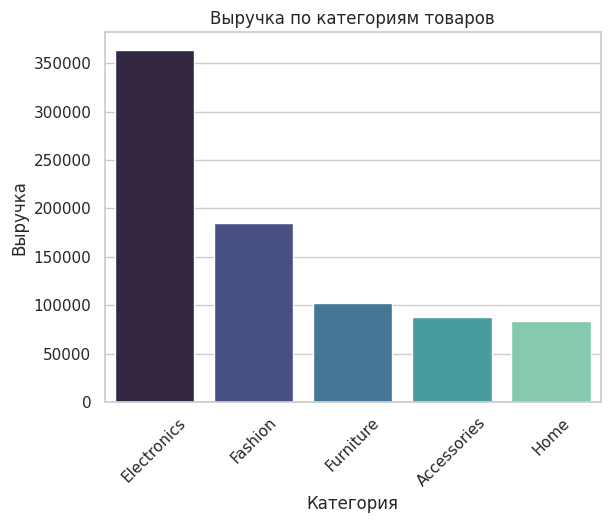

In [20]:
sns.barplot(
    x=revenue_by_category.index,
    y=revenue_by_category.values,
    hue=revenue_by_category.index,
    palette="mako",
    legend=False
)

plt.title("Выручка по категориям товаров")
plt.xlabel("Категория")
plt.ylabel("Выручка")
plt.xticks(rotation=45)
plt.show()

Наибольшую выручку принесла категория Electronics.

### Динамика продаж по месяцам

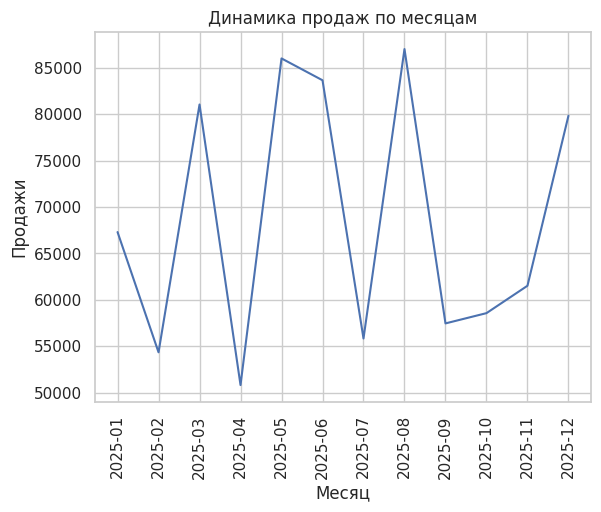

In [21]:
sns.lineplot(
    x=monthly_sales_sorted.index,
    y=monthly_sales_sorted.values
)

plt.title("Динамика продаж по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Продажи")
plt.xticks(rotation=90)
plt.show()

Наибольшая выручка была в августе, самая низкая - в апреле. За один год данных нельзя уверенно определить сезонность.

### Распределение выручки от заказов

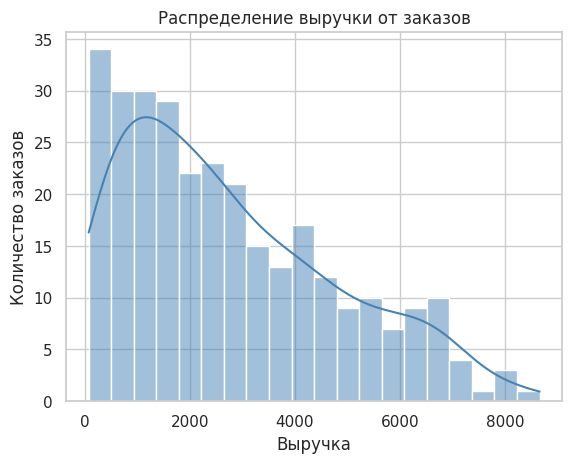

In [22]:
sns.histplot(df["revenue"], bins=20, kde=True, color="steelblue")

plt.title("Распределение выручки от заказов")
plt.xlabel("Выручка")
plt.ylabel("Количество заказов")
plt.show()

Большинство заказов имеют относительно небольшую выручку, а дорогие заказы встречаются реже.

### Распределение методов оплаты

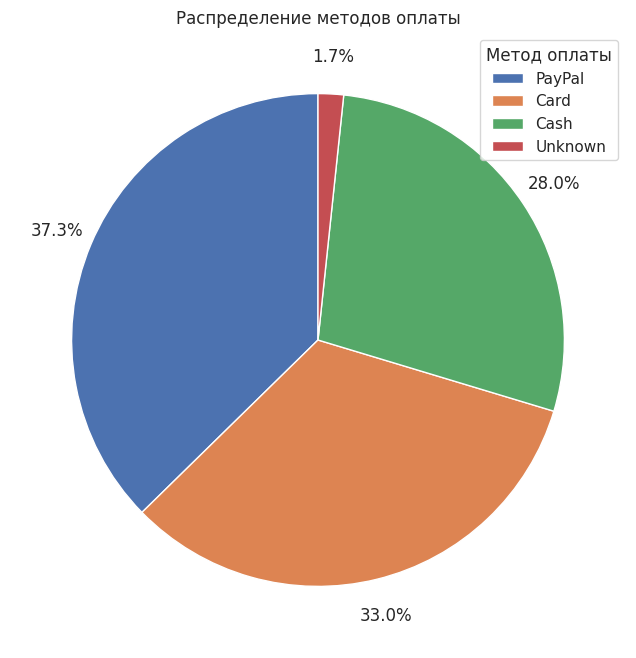

In [23]:
payment_count = df["payment_method"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    payment_count.values,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=1.15
)

plt.title("Распределение методов оплаты")
plt.legend(payment_count.index, title="Метод оплаты", loc="best")
plt.show()

График показывает доли разных способов оплаты. Доля Unknown небольшая.

### Самые популярные товары

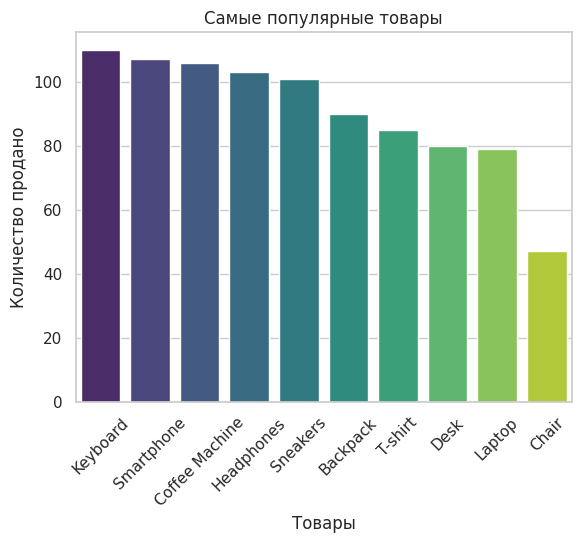

In [24]:
top_products = (
    df.groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

sns.barplot(
    x=top_products.index,
    y=top_products.values,
    hue=top_products.index,
    palette="viridis",
    legend=False
)

plt.title("Самые популярные товары")
plt.xlabel("Товары")
plt.ylabel("Количество продано")
plt.xticks(rotation=45)
plt.show()

Самым популярным товаром оказался Keyboard. Также много продаж было у Smartphone и Coffee Machine.